# Text Clustering

## Anggota Kelompok
- Najla Zahira (25031554041)
- Moza Athaillah Azzahra (25031554185)

Dataset
https://drive.google.com/file/d/1Lioi1yyYc44BMFIfFMDilfjPqPDDxrZC/view?usp=sharing

## Step 1 — Load Dataset dan Persiapan Fitur

Pada tahap ini, dataset hasil feature engineering dari Exercise 5 dimuat untuk digunakan dalam proses text clustering. Dataset berisi metadata artikel, yaitu nomor, judul, dan kategori topik, serta fitur numerik TF-IDF yang merepresentasikan karakteristik teks setiap artikel.

Sebelum clustering dilakukan, dataset diperiksa untuk memastikan jumlah dokumen, jumlah fitur, kelengkapan nilai, dan tipe data sudah sesuai. Kolom metadata dipisahkan dari matriks fitur agar algoritma mengelompokkan dokumen berdasarkan representasi teks, bukan berdasarkan nomor, judul, atau kategori yang telah ditentukan sebelumnya.

In [3]:

import pandas as pd
import numpy as np

# 1. Memuat dataset hasil feature engineering
df = pd.read_csv('hasil_tfidf.csv')

print("=== INFORMASI DATASET ===")
print(f"Jumlah dokumen : {df.shape[0]}")
print(f"Jumlah kolom   : {df.shape[1]}")

# 2. Menentukan kolom metadata
metadata_cols = ['no', 'judul', 'topik']

# Memastikan semua kolom metadata tersedia
missing_metadata = [
    col for col in metadata_cols
    if col not in df.columns
]

if missing_metadata:
    raise ValueError(
        f"Kolom metadata tidak ditemukan: {missing_metadata}"
    )

# 3. Memisahkan metadata dan fitur TF-IDF
metadata = df[metadata_cols].copy()

feature_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

# Mengambil hanya fitur numerik TF-IDF
X_tfidf = df[feature_cols].to_numpy(dtype=float)

# 4. Memeriksa karakteristik matriks fitur
print("\n=== MATRIKS FITUR TF-IDF ===")
print(f"Jumlah fitur     : {X_tfidf.shape[1]}")
print(f"Ukuran matriks   : {X_tfidf.shape}")
print(f"Semua nilai finite: {np.isfinite(X_tfidf).all()}")
print(f"Semua nilai nonnegatif: {(X_tfidf >= 0).all()}")

# 5. Memeriksa data kosong dan baris nol
print("\n=== PEMERIKSAAN DATA ===")
print("Metadata kosong:")
display(metadata.isna().sum().to_frame('Jumlah Kosong'))

zero_rows = np.all(X_tfidf == 0, axis=1)
print(f"Jumlah dokumen dengan semua fitur nol: {zero_rows.sum()}")

# 6. Menampilkan contoh metadata dan fitur
print("\n=== CONTOH METADATA ===")
display(metadata.head())

print("\n=== CONTOH FITUR TF-IDF ===")
display(
    pd.DataFrame(
        X_tfidf[:5, :10],
        columns=feature_cols[:10]
    ).round(4)
)


=== INFORMASI DATASET ===
Jumlah dokumen : 100
Jumlah kolom   : 1503

=== MATRIKS FITUR TF-IDF ===
Jumlah fitur     : 1500
Ukuran matriks   : (100, 1500)
Semua nilai finite: True
Semua nilai nonnegatif: True

=== PEMERIKSAAN DATA ===
Metadata kosong:


,Jumlah Kosong
no,0
judul,0
topik,0


Jumlah dokumen dengan semua fitur nol: 0

=== CONTOH METADATA ===


,no,judul,topik
0,1,Algoritma bias,Computer Science
1,2,Algoritma Lanczos,Computer Science
2,3,ASCII,Computer Science
3,4,Karakter null,Computer Science
4,5,Komputasi optis,Computer Science



=== CONTOH FITUR TF-IDF ===


,000,01,02,03,05,07,10,100,11,12
0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0
1,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0
2,0.0000,0.0,0.0,0.0,0.0,0.0,0.0212,0.0,0.0,0.0
3,0.0314,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0
4,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0


## Step 2 — Hierarchical Clustering

Hierarchical Clustering merupakan metode clustering yang membentuk struktur kelompok secara bertahap. Pada pendekatan agglomerative, setiap dokumen awalnya dianggap sebagai satu cluster tersendiri. Selanjutnya, dua cluster yang paling dekat digabungkan secara berulang hingga terbentuk struktur hierarki.

Pada eksperimen ini, digunakan tiga metode pengukuran jarak antarkelompok, yaitu Single Linkage, Complete Linkage, dan Average Linkage. Jarak antardokumen dihitung menggunakan Cosine Distance berdasarkan fitur TF-IDF.

Untuk membandingkan hasil ketiga metode, jumlah cluster ditetapkan sama. Hasil pengelompokan kemudian dapat dianalisis berdasarkan distribusi anggota dan karakteristik artikel pada setiap cluster.

In [24]:

import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_distances

# 1. Menghitung jarak Cosine antardokumen
distance_matrix = cosine_distances(X_tfidf)

print("Ukuran matriks jarak:", distance_matrix.shape)
print("Rentang nilai jarak:",
      distance_matrix.min(),
      "hingga",
      distance_matrix.max())

# 2. Menentukan jumlah cluster untuk eksperimen pembanding
NUM_CLUSTERS = 4

# 3. Menyiapkan DataFrame untuk menyimpan hasil
hierarchical_results = metadata.copy()

# 4. Menjalankan tiga metode linkage
linkage_methods = ['single', 'complete', 'average']

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=NUM_CLUSTERS,
        metric='precomputed',
        linkage=method
    )

    labels = model.fit_predict(distance_matrix)

    hierarchical_results[f'hc_{method}'] = labels

print("\nHierarchical Clustering selesai.")
display(hierarchical_results.head(10))


Ukuran matriks jarak: (100, 100)
Rentang nilai jarak: 0.0 hingga 0.9967718258764321

Hierarchical Clustering selesai.


,no,judul,topik,hc_single,hc_complete,hc_average
0,1,Algoritma bias,Computer Science,0,2,0
1,2,Algoritma Lanczos,Computer Science,0,2,0
2,3,ASCII,Computer Science,0,3,0
3,4,Karakter null,Computer Science,0,3,0
4,5,Komputasi optis,Computer Science,0,0,0
5,6,Membangkitkan Kombinasi,Computer Science,0,0,0
6,7,Komputasi neuromorfik,Computer Science,0,2,0
7,8,Teori otomata,Computer Science,0,1,2
8,9,Kecerdasan buatan,AI,0,2,0
9,10,Agen otonom,AI,0,0,0


Membandingkan distribusi cluster

In [25]:

for method in linkage_methods:
    column_name = f'hc_{method}'

    print(f"\n=== Distribusi Cluster: {method.upper()} ===")

    counts = (
        hierarchical_results[column_name]
        .value_counts()
        .sort_index()
        .rename_axis('Cluster')
        .reset_index(name='Jumlah Dokumen')
    )

    counts['Persentase (%)'] = (
        counts['Jumlah Dokumen']
        / len(hierarchical_results)
        * 100
    ).round(2)

    display(counts)



=== Distribusi Cluster: SINGLE ===


,Cluster,Jumlah Dokumen,Persentase (%)
0,0,97,97.0
1,1,1,1.0
2,2,1,1.0
3,3,1,1.0



=== Distribusi Cluster: COMPLETE ===


,Cluster,Jumlah Dokumen,Persentase (%)
0,0,35,35.0
1,1,15,15.0
2,2,45,45.0
3,3,5,5.0



=== Distribusi Cluster: AVERAGE ===


,Cluster,Jumlah Dokumen,Persentase (%)
0,0,93,93.0
1,1,3,3.0
2,2,3,3.0
3,3,1,1.0


Dendogram

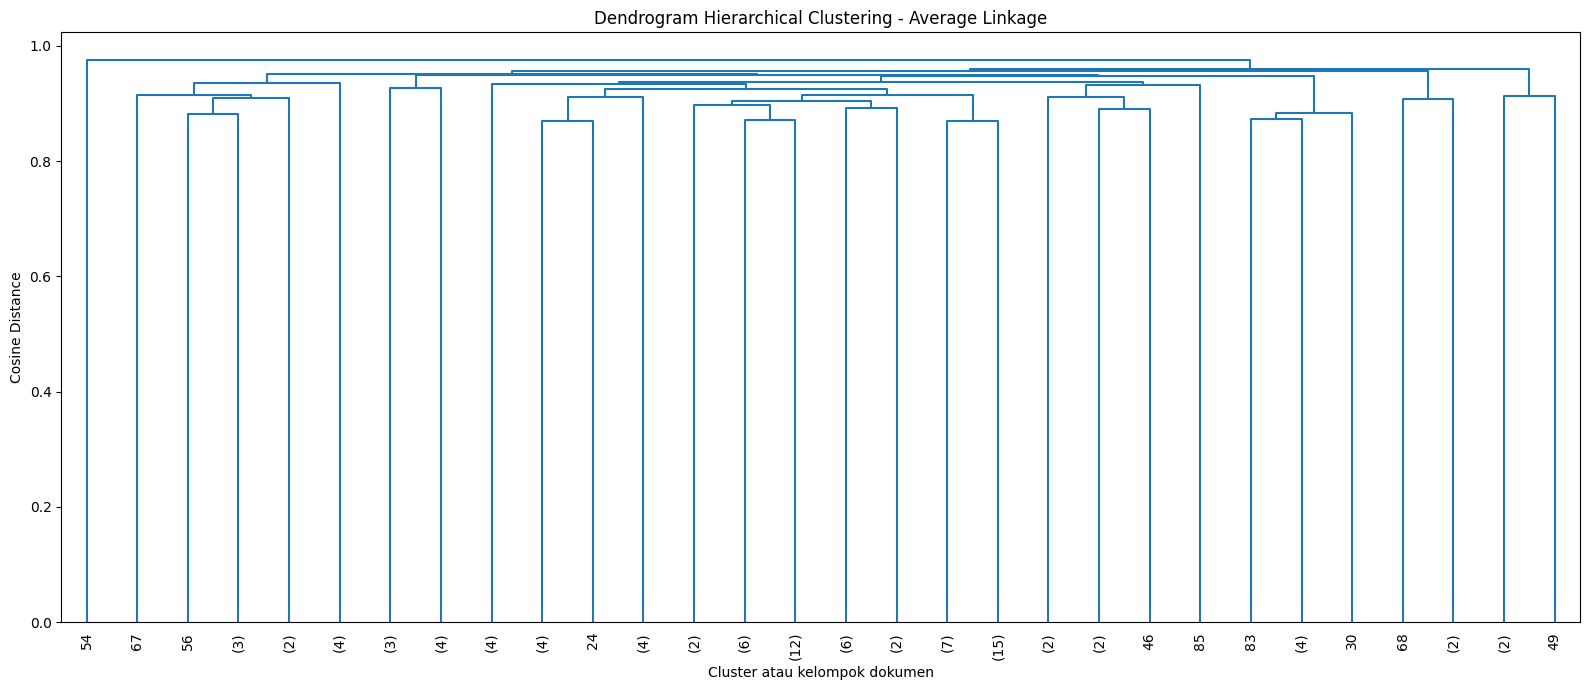

In [26]:

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# Mengubah matriks jarak persegi menjadi format jarak berpasangan
condensed_distances = squareform(distance_matrix, checks=True)

# Membentuk struktur hierarki menggunakan Average Linkage
Z_average = linkage(
    condensed_distances,
    method='average',
    optimal_ordering=True
)

# Membuat dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    Z_average,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90
)

plt.title('Dendrogram Hierarchical Clustering - Average Linkage')
plt.xlabel('Cluster atau kelompok dokumen')
plt.ylabel('Cosine Distance')
plt.tight_layout()
plt.show()


## Step 3 — Evaluasi kualitas Hierarchical Clustering menggunakan Silhouette Score.

Menghitung Silhouette Score

In [27]:

from sklearn.metrics import silhouette_score
import pandas as pd

silhouette_results = []

for method in linkage_methods:
    cluster_labels = hierarchical_results[f'hc_{method}']

    score = silhouette_score(
        distance_matrix,
        cluster_labels,
        metric='precomputed'
    )

    silhouette_results.append({
        'Metode': method.capitalize() + ' Linkage',
        'Jumlah Cluster': cluster_labels.nunique(),
        'Silhouette Score': score
    })

silhouette_df = pd.DataFrame(silhouette_results)

silhouette_df = silhouette_df.sort_values(
    by='Silhouette Score',
    ascending=False
).reset_index(drop=True)

display(silhouette_df.round(4))


,Metode,Jumlah Cluster,Silhouette Score
0,Average Linkage,4,0.0316
1,Complete Linkage,4,0.0252
2,Single Linkage,4,0.0220


Visualisasi perbandingan score

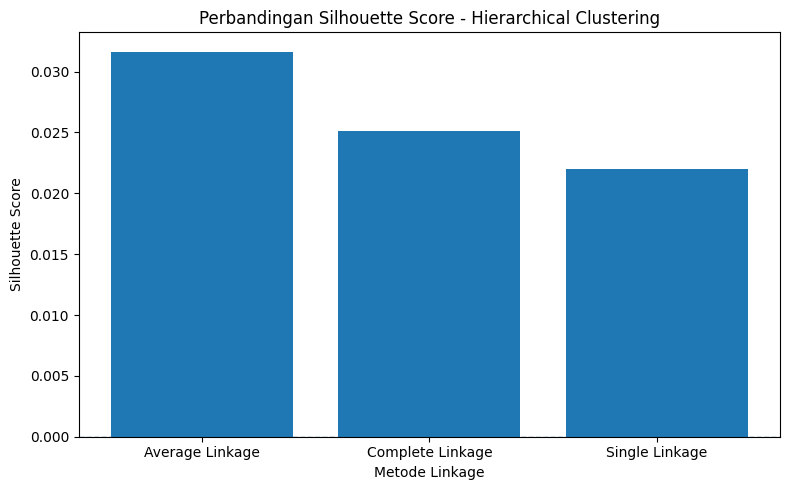

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    silhouette_df['Metode'],
    silhouette_df['Silhouette Score']
)

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1
)

plt.title('Perbandingan Silhouette Score - Hierarchical Clustering')
plt.xlabel('Metode Linkage')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


Elbow dan Silhouette untuk K-Means

,k,Inertia,Silhouette Score
0,2,89.1054,0.0242
1,3,87.4408,0.0318
2,4,85.8665,0.0325
3,5,84.6229,0.0259
4,6,83.4625,0.0280
5,7,81.1487,0.0458
6,8,80.4654,0.0343
7,9,78.6674,0.0512
8,10,77.6331,0.0431


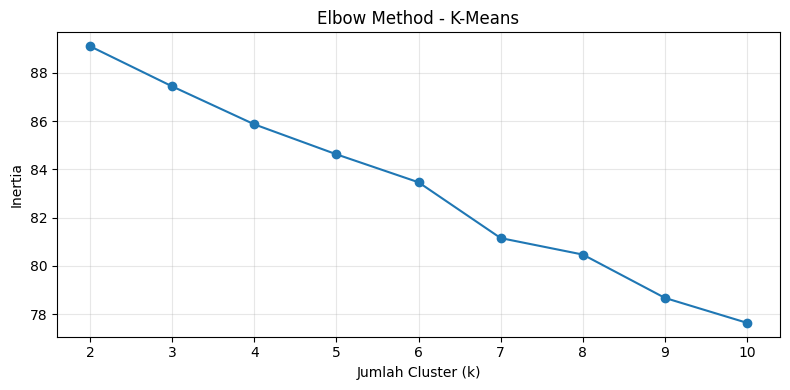

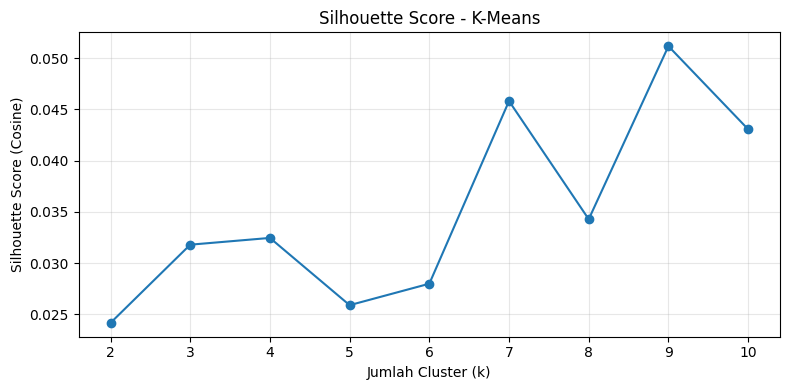

In [29]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

k_values = range(2, 11)

kmeans_evaluation = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf)

    score = silhouette_score(
        X_tfidf,
        labels,
        metric='cosine'
    )

    kmeans_evaluation.append({
        'k': k,
        'Inertia': model.inertia_,
        'Silhouette Score': score
    })

kmeans_eval_df = pd.DataFrame(kmeans_evaluation)

display(kmeans_eval_df.round(4))

# Visualisasi Elbow Method
plt.figure(figsize=(8, 4))
plt.plot(
    kmeans_eval_df['k'],
    kmeans_eval_df['Inertia'],
    marker='o'
)
plt.title('Elbow Method - K-Means')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualisasi Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(
    kmeans_eval_df['k'],
    kmeans_eval_df['Silhouette Score'],
    marker='o'
)
plt.title('Silhouette Score - K-Means')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score (Cosine)')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Step 4 — Implementasi K-Means Clustering

K-Means merupakan algoritma clustering yang membagi data ke dalam sejumlah cluster berdasarkan kedekatan setiap data terhadap pusat cluster (*centroid*). Algoritma ini bekerja secara iteratif dengan menentukan centroid, mengelompokkan dokumen berdasarkan kedekatannya, kemudian memperbarui posisi centroid hingga mencapai kondisi konvergen atau memenuhi batas iterasi.

Pada eksperimen sebelumnya, jumlah cluster dievaluasi menggunakan Elbow Method dan Silhouette Score untuk nilai k dari 2 hingga 10. Berdasarkan hasil evaluasi tersebut, k = 9 memperoleh Silhouette Score tertinggi sebesar 0,0512.

Oleh karena itu, pada tahap ini K-Means dijalankan menggunakan sembilan cluster sebagai kandidat utama. Hasilnya akan dianalisis berdasarkan distribusi dokumen, karakteristik artikel, dan kata-kata dominan pada setiap cluster. Nilai k = 9 tetap diperlakukan sebagai kandidat eksperimen karena Silhouette Score yang diperoleh masih rendah.

In [10]:

from sklearn.cluster import KMeans
import pandas as pd

# 1. Menentukan jumlah cluster berdasarkan evaluasi sebelumnya
k_final = 9

# 2. Membuat dan menjalankan model K-Means
kmeans_model = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_tfidf)

# 3. Menyimpan hasil clustering bersama metadata dokumen
kmeans_results = metadata.copy()
kmeans_results['kmeans_cluster'] = kmeans_labels

# 4. Menampilkan beberapa contoh hasil clustering
display(kmeans_results.head(10))


,no,judul,topik,kmeans_cluster
0,1,Algoritma bias,Computer Science,2
1,2,Algoritma Lanczos,Computer Science,2
2,3,ASCII,Computer Science,0
3,4,Karakter null,Computer Science,0
4,5,Komputasi optis,Computer Science,8
5,6,Membangkitkan Kombinasi,Computer Science,2
6,7,Komputasi neuromorfik,Computer Science,1
7,8,Teori otomata,Computer Science,1
8,9,Kecerdasan buatan,AI,3
9,10,Agen otonom,AI,3


Melihat distribusi cluster

In [11]:

cluster_counts = (
    kmeans_results['kmeans_cluster']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .reset_index(name='Jumlah Dokumen')
)

cluster_counts['Persentase (%)'] = (
    cluster_counts['Jumlah Dokumen']
    / len(kmeans_results)
    * 100
).round(2)

display(cluster_counts)

print("Jumlah dokumen:", len(kmeans_results))
print("Jumlah cluster yang terbentuk:",
      kmeans_results['kmeans_cluster'].nunique())


,Cluster,Jumlah Dokumen,Persentase (%)
0,0,6,6.0
1,1,15,15.0
2,2,6,6.0
3,3,20,20.0
4,4,8,8.0
5,5,11,11.0
6,6,6,6.0
7,7,3,3.0
8,8,25,25.0


Jumlah dokumen: 100
Jumlah cluster yang terbentuk: 9


## Step 5 — Interpretasi Hasil Clustering

Setelah K-Means menghasilkan sembilan cluster, tahap selanjutnya adalah menganalisis karakteristik setiap kelompok. Analisis dilakukan dengan memeriksa judul artikel, kata-kata dominan berdasarkan bobot TF-IDF, dan distribusi kategori topik asli.

Judul artikel digunakan untuk memberikan gambaran awal mengenai isi cluster, sedangkan kata-kata dominan membantu mengidentifikasi istilah yang paling menonjol pada dokumen-dokumen dalam kelompok tersebut. Kategori topik asli digunakan sebagai pembanding untuk melihat kesesuaian dan keberagaman topik di dalam cluster.

Analisis ini bersifat interpretatif. Kesamaan kategori asli tidak menjadi syarat bahwa clustering berhasil, karena algoritma mengelompokkan dokumen berdasarkan fitur TF-IDF, bukan berdasarkan label kategori.

Menampilkan judul artikel per cluster

In [12]:

for cluster_id in sorted(kmeans_results['kmeans_cluster'].unique()):
    cluster_data = kmeans_results[
        kmeans_results['kmeans_cluster'] == cluster_id
    ]

    print(f"\n{'=' * 60}")
    print(f"CLUSTER {cluster_id} — {len(cluster_data)} dokumen")
    print('=' * 60)

    for title in cluster_data['judul']:
        print("-", title)



CLUSTER 0 — 6 dokumen
- ASCII
- Karakter null
- Analisis leksikal
- Kode
- Open Database Connectivity
- Konversi data

CLUSTER 1 — 15 dokumen
- Komputasi neuromorfik
- Teori otomata
- Jaringan saraf tiruan
- Pengenalan tulisan tangan
- Diagram alir data
- Penambangan data pendidikan
- Pola serangan
- Manajemen data
- Data tertaut
- Injeksi SQL
- Mahadata
- Normalisasi pangkalan data
- Penggalian data
- General protection fault
- Keamanan jaringan

CLUSTER 2 — 6 dokumen
- Algoritma bias
- Algoritma Lanczos
- Membangkitkan Kombinasi
- Algoritma genetik
- Algoritma semut
- Algoritma pencarian

CLUSTER 3 — 20 dokumen
- Kecerdasan buatan
- Agen otonom
- Apple Intelligence
- Claude (model bahasa)
- Dampak lingkungan dari kecerdasan buatan
- Etika dalam kecerdasan buatan
- Halusinasi (kecerdasan buatan)
- Keamanan kecerdasan buatan
- Penerapan kecerdasan buatan
- Kecerdasan buatan generatif
- Kecerdasan buatan simbolik
- Keruntuhan model
- Kesadaran buatan
- Masalah pengendalian kecerdasan b

Distribusi kategori pada setiap cluster

In [14]:

# Menghitung jumlah dokumen berdasarkan cluster dan topik asli
topic_distribution = pd.crosstab(
    kmeans_results['kmeans_cluster'],
    kmeans_results['topik']
)

print("=== JUMLAH DOKUMEN PER TOPIK DALAM SETIAP CLUSTER ===")
display(topic_distribution)

# Menghitung persentase topik dalam setiap cluster
topic_percentage = (
    topic_distribution
    .div(topic_distribution.sum(axis=1), axis=0)
    * 100
).round(2)

print("=== PERSENTASE TOPIK DALAM SETIAP CLUSTER (%) ===")
display(topic_percentage)


=== JUMLAH DOKUMEN PER TOPIK DALAM SETIAP CLUSTER ===


topik,AI,Computer Science,Data & Statistics,Technology & Internet
kmeans_cluster,,,,
0,0,4,1,1
1,2,4,8,1
2,2,4,0,0
3,18,1,1,0
4,0,0,1,7
5,0,0,5,6
6,0,0,0,6
7,0,0,1,2
8,3,17,3,2


=== PERSENTASE TOPIK DALAM SETIAP CLUSTER (%) ===


topik,AI,Computer Science,Data & Statistics,Technology & Internet
kmeans_cluster,,,,
0,0.00,66.67,16.67,16.67
1,13.33,26.67,53.33,6.67
2,33.33,66.67,0.00,0.00
3,90.00,5.00,5.00,0.00
4,0.00,0.00,12.50,87.50
5,0.00,0.00,45.45,54.55
6,0.00,0.00,0.00,100.00
7,0.00,0.00,33.33,66.67
8,12.00,68.00,12.00,8.00


## Step 6 — Analisis Kata Dominan pada Setiap Cluster

Analisis kata dominan dilakukan untuk mengidentifikasi istilah yang memiliki bobot TF-IDF rata-rata tinggi pada dokumen dalam setiap cluster. Istilah-istilah tersebut digunakan untuk membantu menjelaskan karakteristik tekstual dari kelompok yang terbentuk.

Pada analisis ini, bobot TF-IDF setiap fitur dirata-ratakan berdasarkan anggota cluster. Beberapa istilah dengan rata-rata bobot tertinggi kemudian ditampilkan sebagai petunjuk untuk menginterpretasikan tema cluster.

Kata dominan tidak secara otomatis menunjukkan topik yang pasti. Oleh karena itu, hasilnya perlu ditafsirkan bersama judul artikel, distribusi kategori asli, dan hasil evaluasi clustering.

In [16]:

# Memastikan daftar fitur hanya berisi kolom TF-IDF
metadata_cols = ['no', 'judul', 'topik']
feature_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

top_n = 10

for cluster_id in sorted(kmeans_results['kmeans_cluster'].unique()):
    # Mengambil indeks dokumen dalam cluster saat ini
    cluster_indices = kmeans_results.index[
        kmeans_results['kmeans_cluster'] == cluster_id
    ]

    # Menghitung rata-rata bobot TF-IDF setiap fitur
    mean_tfidf = df.loc[
        cluster_indices, feature_cols
    ].mean(axis=0)

    # Mengambil 10 fitur dengan bobot rata-rata tertinggi
    top_terms = mean_tfidf.sort_values(
        ascending=False
    ).head(top_n)

    print(f"\n{'=' * 55}")
    print(f"CLUSTER {cluster_id} — KATA DOMINAN")
    print('=' * 55)

    for term, score in top_terms.items():
        print(f"{term}: {score:.4f}")



CLUSTER 0 — KATA DOMINAN
karakter: 0.2865
kode: 0.2112
ascii: 0.1268
konversi: 0.1266
null: 0.0959
driver: 0.0935
sandi: 0.0872
leksikal: 0.0846
basis data: 0.0814
basis: 0.0752

CLUSTER 1 — KATA DOMINAN
serang: 0.0819
jaring: 0.0615
simbol: 0.0595
pola: 0.0578
ajar: 0.0563
alir: 0.0466
tulis tangan: 0.0460
neuron: 0.0451
sql: 0.0446
saraf: 0.0430

CLUSTER 2 — KATA DOMINAN
algoritma: 0.2698
cari: 0.1459
himpun: 0.1134
jalur: 0.1105
matriks: 0.0985
vektor: 0.0932
kombinasi: 0.0850
bias: 0.0802
genetika: 0.0703
populasi: 0.0660

CLUSTER 3 — KATA DOMINAN
ai: 0.1822
model: 0.1405
cerdas: 0.1230
cerdas buat: 0.0996
latih: 0.0764
gambar: 0.0613
hasil: 0.0587
mampu: 0.0530
manusia: 0.0520
tingkat: 0.0501

CLUSTER 4 — KATA DOMINAN
teknologi: 0.1744
internet: 0.1267
atm: 0.1028
frekuensi: 0.1001
kabel: 0.0824
telepon: 0.0712
dsl: 0.0691
indonesia: 0.0685
ajar: 0.0652
informasi: 0.0605

CLUSTER 5 — KATA DOMINAN
bisnis: 0.1759
elektronik: 0.1343
transaksi: 0.1050
pasar: 0.0929
dokumen: 0.0899
la

## Step 7 — Evaluasi dan Perbandingan Algoritma Clustering

Evaluasi akhir dilakukan dengan membandingkan hasil K-Means dan Hierarchical Clustering menggunakan jumlah cluster yang sama. Silhouette Score digunakan untuk menilai kekompakan dan pemisahan cluster, sedangkan distribusi anggota, judul artikel, kata dominan, dan kategori topik asli digunakan untuk mendukung interpretasi hasil.

Perbandingan ini membantu mengidentifikasi metode yang relatif lebih sesuai pada dataset yang digunakan. Namun, skor evaluasi yang rendah perlu dipertimbangkan dalam menarik kesimpulan. Hasil clustering tidak hanya dinilai berdasarkan nilai metrik, tetapi juga berdasarkan keterjelasan tema dan karakteristik kelompok yang terbentuk.

In [17]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

# K-Means: menggunakan hasil k = 9 yang sudah dibuat
kmeans_score_9 = silhouette_score(
    X_tfidf,
    kmeans_results['kmeans_cluster'],
    metric='cosine'
)

# Hierarchical Clustering: Average Linkage, k = 9
hierarchical_avg_9 = AgglomerativeClustering(
    n_clusters=9,
    metric='precomputed',
    linkage='average'
)

hierarchical_labels_9 = hierarchical_avg_9.fit_predict(
    distance_matrix
)

hierarchical_score_9 = silhouette_score(
    distance_matrix,
    hierarchical_labels_9,
    metric='precomputed'
)

# Menyusun tabel perbandingan
comparison_df = pd.DataFrame({
    'Metode': [
        'K-Means',
        'Hierarchical - Average Linkage'
    ],
    'Jumlah Cluster': [9, 9],
    'Silhouette Score': [
        kmeans_score_9,
        hierarchical_score_9
    ]
})

display(comparison_df.round(4))


,Metode,Jumlah Cluster,Silhouette Score
0,K-Means,9,0.0512
1,Hierarchical - Average Linkage,9,0.0473


### Evaluasi dan Perbandingan Hasil Clustering

Evaluasi akhir dilakukan dengan membandingkan algoritma K-Means dan Hierarchical Clustering menggunakan metode Average Linkage, dengan jumlah cluster yang sama, yaitu 9 cluster. Berdasarkan hasil pengujian menggunakan Silhouette Score dengan metrik cosine, K-Means memperoleh skor sebesar 0,0512, sedangkan Hierarchical Clustering dengan Average Linkage memperoleh skor sebesar 0,0473.

K-Means menghasilkan Silhouette Score yang sedikit lebih tinggi dibandingkan Hierarchical Clustering. Hal ini menunjukkan bahwa, berdasarkan metrik evaluasi yang digunakan, K-Means memberikan hasil pengelompokan yang relatif lebih baik pada dataset ini. Meskipun demikian, kedua skor masih tergolong rendah dan mendekati nol, sehingga pemisahan antarkelompok dokumen belum terlihat kuat.

Jumlah 9 cluster dipilih sebagai kandidat berdasarkan hasil pengujian beberapa nilai cluster pada K-Means. Pemilihan ini tidak berarti bahwa 9 merupakan jumlah cluster yang paling optimal secara mutlak. Oleh karena itu, hasil evaluasi kuantitatif perlu dipertimbangkan bersama distribusi anggota cluster, judul artikel, kata-kata dominan TF-IDF, serta kesesuaian topik artikel di dalam setiap cluster.

Secara keseluruhan, K-Means menjadi metode yang sedikit lebih baik di antara kedua metode yang dibandingkan berdasarkan Silhouette Score. Namun, kualitas pengelompokan masih perlu ditafsirkan secara hati-hati karena nilai evaluasinya rendah. Hasil clustering dapat membantu menemukan kemiripan topik antardokumen, tetapi belum menunjukkan pemisahan kelompok yang benar-benar kuat.